In [29]:
!pip install gym-bandits

In [30]:
import gym
import gym_bandits
import numpy as np

In [31]:
env=gym.make('MultiarmedBandits-v0')

In [32]:
print(env.observation_space)

Discrete(1)


In [33]:
print(env.action_space)

Discrete(10)


In [36]:
n_arms = env.action_space.n
num_episodes = 500

epsilon = 0.1

q_values = np.zeros(n_arms)
counts = np.zeros(n_arms)
reward_sums = np.zeros(n_arms)

all_rewards = []
action_history = []

import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

for episode in range(num_episodes):
  env.reset()
  if np.random.rand() < epsilon:
    action = env.action_space.sample()
  else:
    action = np.argmax(q_values)
  observation, reward, done, info = env.step(action)
  counts[action] += 1
  reward_sums[action] += reward
  q_values[action] = reward_sums[action] / counts[action]

  all_rewards.append(reward)
  action_history.append(action)
env.close()

print("Estimated Q-values for each arm: ", np.round(q_values, 2))
print("Number of times each arm was selected: ", counts.astype(int))
print("Average reward overall episodes: ", round(np.mean(all_rewards), 3))

Estimated Q-values for each arm:  [-0.92 -0.05 -0.03 -0.16 -0.02 -1.51 -0.77 -0.03 -0.03 -0.04]
Number of times each arm was selected:  [  5   6  81   7 195   2   8  35 140  21]
Average reward overall episodes:  -0.056


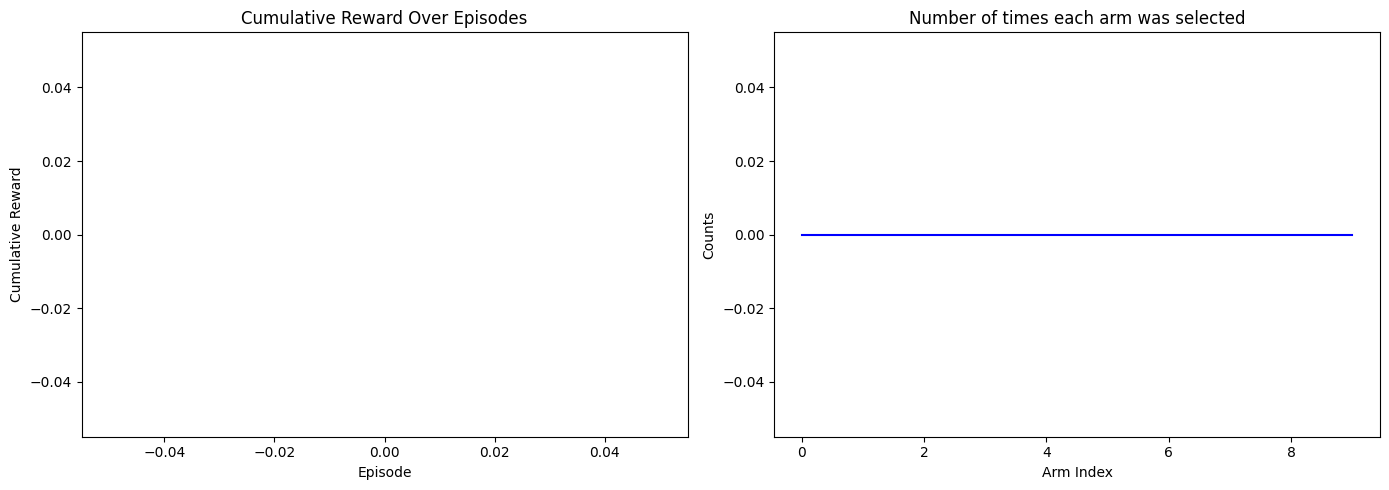

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,5))

plt.subplot(1,2,1)
plt.plot(np.cumsum(all_rewards), color = 'blue')
plt.title("Cumulative Reward Over Episodes")
plt.xlabel("Episode")
plt.ylabel("Cumulative Reward")

plt.subplot(1,2,2)
plt.plot(np.arange(n_arms), counts, color = 'blue')
plt.title("Number of times each arm was selected")
plt.xlabel("Arm Index")
plt.ylabel("Counts")
plt.tight_layout()
plt.show()